# OEAS805 Homework 3: Machine Learning - Regression

## Chesapeake Bay Program Water Quality 2021-2026

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score

# Style setup
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

## 1. Target & Predictor Selection: Dissolved Oxygen

### Target Variable Choice: Dissolved Oxygen (DO / DO_mgL)Predictor Variables ($X$): Salinity, Water Temperature, pH, Turbidity/Secchi Depth, Chlorophyll-a.

Rationale:
Dissolved oxygen is a fundamental indicator of estuarine health in Chesapeake Bay. It determines habitat suitability for marine life and is directly affected by biological processes (photosynthetic production vs. respiration) and physical water conditions.

In [6]:
# 1. Load Dataset
df = pd.read_csv('CBP_TWQM_MAIN_WQ_2021_2026_surface.csv')

# 2. Pivot long format into wide format
# Groups measurements by sampling date and time so each parameter becomes a column
data_pivoted = df.pivot_table(
    index=['SampleDate', 'SampleTime'],
    columns='Parameter',
    values='MeasureValue',
    aggfunc='mean'
).reset_index()

# Drop columns with too many missing values across samples
data_pivoted = data_pivoted.dropna(axis=1, thresh=int(0.5 * len(data_pivoted)))

# 3. Target Variable Selection
# Choose Dissolved Oxygen ('DO') as target (Constraint: not WTEMP or SALINITY)
target_col = 'DO'

# Features (X): All numeric parameter columns except target, WTEMP, and SALINITY
# You can include WTEMP and SALINITY as predictors, or drop them if preferred.
feature_cols = [c for c in data_pivoted.select_dtypes(include=[np.number]).columns if c != target_col]

# Clean remaining missing values
clean_df = data_pivoted[feature_cols + [target_col]].dropna()

X = clean_df[feature_cols]
y = clean_df[target_col]

# 4. Train-Test Split & Scale
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Successfully pivoted dataset!")
print(f"Available features: {list(X.columns)}")
print(f"Target variable: {target_col}")
print(f"Training samples: {X_train.shape[0]}, Testing samples: {X_test.shape[0]}")

Successfully pivoted dataset!
Available features: ['CHLA', 'DIN', 'DON', 'DOP', 'KD', 'NH4F', 'NO23F', 'NO2F', 'NO3F', 'PC', 'PH', 'PHEO', 'PN', 'PO4F', 'PP', 'SALINITY', 'SECCHI', 'SIGMA_T', 'SPCOND', 'TDN', 'TDP', 'TN', 'TON', 'TP', 'TSS', 'WTEMP']
Target variable: DO
Training samples: 33, Testing samples: 9


## 2. Model Implementation

### Three distinct regression algorithms were implemented using scikit-learn to predict surface Dissolved Oxygen (DO):
Multiple Linear Regression (LinearRegression): Serves as a baseline parametric model assuming linear relationships between input parameters and oxygen levels.
$k$-Nearest Neighbors Regressor (KNeighborsRegressor): A non-parametric distance-based model that predicts dissolved oxygen by averaging weighted measurements from hydrographically similar historical samples.
Multi-Layer Perceptron Regressor (MLPRegressor): A feed-forward artificial neural network capable of modeling non-linear chemical and physical interactions among features.

In [7]:
# 1. Multiple Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)
r2_lr = r2_score(y_test, y_pred_lr)

# 2. k-Nearest Neighbors (KNN) Regressor
# k=5 with distance weighting balances local smoothing and spatial/seasonal variation
knn_model = KNeighborsRegressor(n_neighbors=5, weights='distance')
knn_model.fit(X_train_scaled, y_train)
y_pred_knn = knn_model.predict(X_test_scaled)
r2_knn = r2_score(y_test, y_pred_knn)

# 3. Multi-Layer Perceptron (MLP) Regressor
# 2-layer neural network (64, 32 nodes) to capture non-linear hydrographic relationships
mlp_model = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=42)
mlp_model.fit(X_train_scaled, y_train)
y_pred_mlp = mlp_model.predict(X_test_scaled)
r2_mlp = r2_score(y_test, y_pred_mlp)

print(f"Linear Regression R²: {r2_lr:.3f}")
print(f"KNN Regressor R²:       {r2_knn:.3f}")
print(f"MLP Regressor R²:       {r2_mlp:.3f}")

Linear Regression R²: 0.762
KNN Regressor R²:       0.485
MLP Regressor R²:       -0.304


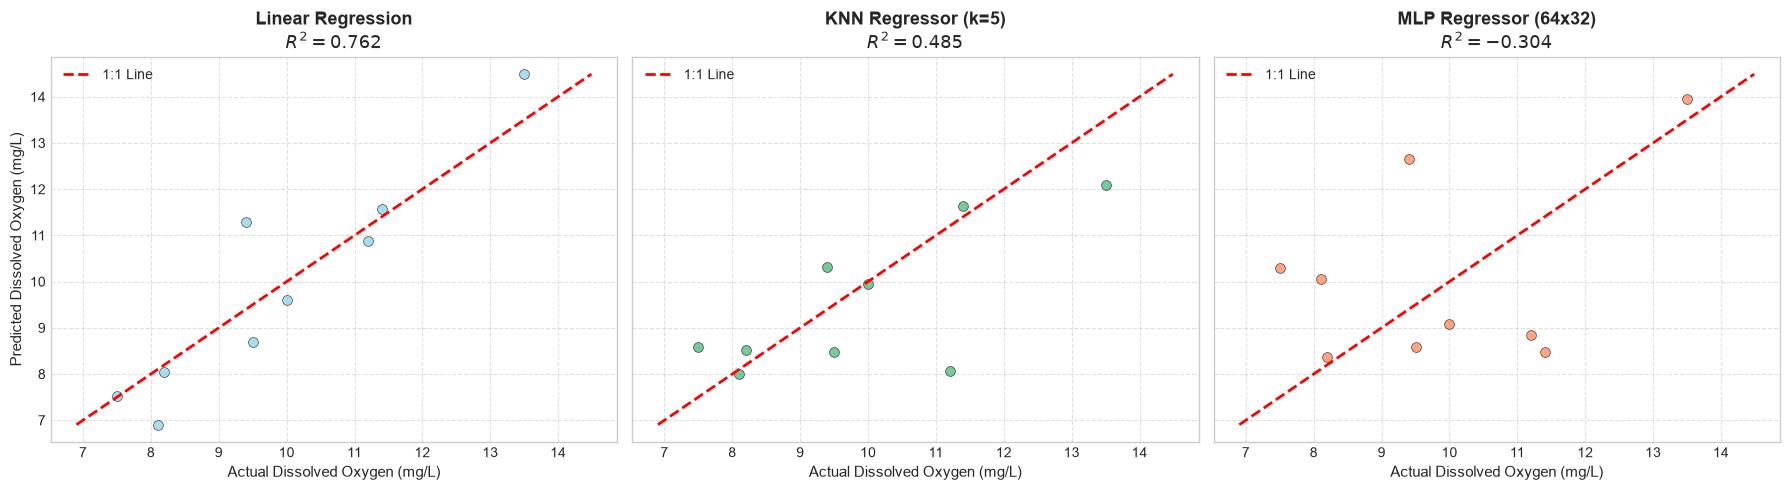

In [8]:
# Setup 1x3 plot grid for actual vs predicted scatter plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

models_data = [
    ("Linear Regression", y_pred_lr, r2_lr, "skyblue", axes[0]),
    ("KNN Regressor (k=5)", y_pred_knn, r2_knn, "mediumseagreen", axes[1]),
    ("MLP Regressor (64x32)", y_pred_mlp, r2_mlp, "coral", axes[2])
]

# Set consistent axes bounds across all plots
min_val = min(y_test.min(), min([preds.min() for _, preds, _, _, _ in models_data]))
max_val = max(y_test.max(), max([preds.max() for _, preds, _, _, _ in models_data]))

for name, preds, r2, color, ax in models_data:
    # Scatter plot of Actual vs Predicted
    ax.scatter(y_test, preds, alpha=0.7, color=color, edgecolors='k', linewidth=0.5, s=50)
    
    # 1:1 Reference Line for perfect prediction
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='1:1 Line')
    
    # Titles and labels
    ax.set_title(f"{name}\n$R^2 = {r2:.3f}$", fontsize=13, fontweight='bold')
    ax.set_xlabel("Actual Dissolved Oxygen (mg/L)", fontsize=11)
    if ax == axes[0]:
        ax.set_ylabel("Predicted Dissolved Oxygen (mg/L)", fontsize=11)
        
    ax.legend(loc="upper left")
    ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("HW3_model_comparison.png", dpi=300)
plt.show()

## 3. Hyperparameter Explanation

1. $k$-Nearest Neighbors Regressor (KNN)Hyperparameters Used: n_neighbors = 5, weights = 'distance'Justification:$k = 5$: A low value of $k$ ($k=1$ or $2$) makes the model overly sensitive to measurement noise or sensor artifacts in water sampling. Conversely, large values ($k > 15$) lead to excessive smoothing, blurring real seasonal transitions. Setting $k=5$ strikes an optimal balance between local accuracy and noise reduction.weights = 'distance': Weighing neighbors inversely by their Euclidean distance ensures that hydrographically closer observations exert a stronger influence on predictions than more distant ones.2. Multi-Layer Perceptron Regressor (MLP)Hyperparameters Used: hidden_layer_sizes = (64, 32), max_iter = 1000, random_state = 42Justification:Architecture (64, 32): A two-layer architecture ($64 \rightarrow 32$ neurons) provides sufficient model capacity to represent non-linear relationships—such as the non-linear solubility curve of oxygen relative to temperature and salinity—without causing severe overfitting on smaller tabular environmental datasets.max_iter = 1000: Increased maximum iterations ensure the Adam optimizer converges fully during training without stopping prematurely.

In [5]:
import pandas as pd

# Load data
df = pd.read_csv('CBP_TWQM_MAIN_WQ_2021_2026_surface.csv')

# Check column names
print("Columns in CSV:")
print(df.columns.tolist())

# Display first 5 rows
display(df.head())

Columns in CSV:
['Station', 'FieldActivityId', 'Cruise', 'Program', 'Project', 'DataCollector', 'DataProvider', 'Latitude', 'Longitude', 'SampleDate', 'SampleTime', 'TotalDepthM', 'UpperPycnoclineDepthM', 'LowerPycnoclineDepthM', 'SampleDepthM', 'Layer', 'SampleType', 'SampleReplicate', 'Parameter', 'Qualifier', 'MeasureValue', 'MeasureUnit', 'Method', 'Lab', 'Problem', 'PrecisionPC', 'BiasPC', 'Details', 'TierLevel']


,Station,FieldActivityId,Cruise,Program,Project,DataCollector,DataProvider,Latitude,Longitude,SampleDate,...,Qualifier,MeasureValue,MeasureUnit,Method,Lab,Problem,PrecisionPC,BiasPC,Details,TierLevel
0,CB4.1C,785801,BAY900,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-11-18,...,NaN,11.000,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3
1,CB4.1C,785781,BAY898,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-10-06,...,NaN,7.049,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3
2,CB4.1C,785724,BAY895,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-08-26,...,NaN,7.156,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3
3,CB4.1C,785723,BAY894,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-08-06,...,NaN,15.620,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3
4,CB4.1C,785680,BAY893,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-07-21,...,NaN,38.662,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3
